# 0. Why hub height and wind errors matter: the physics

Background for the benchmark. Using the one-year example weather file that ships with windpowerlib (2010; wind at 10 m and 80 m) and the power curve of a 2 MW-class turbine (Senvion MM92, 100 m hub), I asked two questions:

1. If you only have wind at another height, how much does the method of extrapolating to hub height change the energy estimate?
2. What does a steady +1 m/s wind forecast error do to energy, and at which wind speeds does it hurt most?

In [1]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from windpowerlib import WindTurbine

PATH = "../data/physics/weather.csv"
URL = "https://raw.githubusercontent.com/wind-python/windpowerlib/dev/example/weather.csv"
if not os.path.exists(PATH):
    os.makedirs(os.path.dirname(PATH), exist_ok=True)
    urllib.request.urlretrieve(URL, PATH)

INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})
pd.set_option("display.width", 160)

In [2]:
weather = pd.read_csv(PATH, header=[0, 1], index_col=0)
weather.columns = [f"{a.split('.')[0]}_{b}" for a, b in weather.columns]   # wind_speed_80, pressure_0, ...
weather.index = pd.to_datetime(weather.index, utc=True)
z0 = 0.15                                                                   # roughness length in the file

mm92 = WindTurbine(turbine_type="MM92/2050", hub_height=100)
curve = mm92.power_curve                                                    # wind_speed (m/s), value (W)

def power_mw(v):
    p = np.interp(v, curve.wind_speed, curve.value) / 1e6
    return np.where(v > curve.wind_speed.max(), 0.0, p)                     # cut-out

v_10, v_80 = weather["wind_speed_10"], weather["wind_speed_80"]
alpha = (np.log(v_80 / v_10) / np.log(80 / 10)).clip(0, 0.6)               # hourly shear exponent
print("median shear exponent:", round(alpha.median(), 3))

median shear exponent: 0.275


## 1. Getting to hub height

The reference is the power law with each hour's own shear exponent, measured between 10 m and 80 m and applied from 80 m. The alternatives are a fixed exponent of 1/7, the log law, and starting from 10 m.

In [3]:
hub = {"hourly shear, from 80 m": v_80 * (100 / 80) ** alpha,
       "log law, from 80 m": v_80 * np.log(100 / z0) / np.log(80 / z0),
       "fixed 1/7, from 80 m": v_80 * (100 / 80) ** (1 / 7),
       "fixed 1/7, from 10 m": v_10 * (100 / 10) ** (1 / 7)}
E = pd.Series({k: power_mw(v).sum() for k, v in hub.items()}, name="annual energy (MWh)")
ext = pd.DataFrame({"annual energy (MWh)": E.round(0),
                    "vs hourly shear (%)": (100 * (E / E.iloc[0] - 1)).round(1)})
ext

,annual energy (MWh),vs hourly shear (%)
"hourly shear, from 80 m",5900.0,0.0
"log law, from 80 m",5608.0,-4.9
"fixed 1/7, from 80 m",5565.0,-5.7
"fixed 1/7, from 10 m",3680.0,-37.6


Starting near hub height, the method matters by about 5%. Starting from 10 m with a textbook exponent loses over a third of the energy, because the real shear here is much stronger than 1/7, especially at night. **Hub-height forecasts are worth paying for.** The benchmark tests this on real forecasts.

## 2. Where a wind error hurts

In [4]:
v = hub["hourly shear, from 80 m"]
err = power_mw(v + 1) - power_mw(v)
print(f"+1 m/s bias: {100 * err.sum() / power_mw(v).sum():+.1f}% of annual energy")
share = pd.Series(err).groupby(np.floor(v.values).astype(int)).sum().div(err.sum()).mul(100).loc[3:14]
share.round(1).rename("share of the extra energy (%)").to_frame().T

+1 m/s bias: +39.1% of annual energy


,3,4,5,6,7,8,9,10,11,12,13,14
share of the extra energy (%),0.9,8.2,19.3,24.5,20.7,16.2,7.9,2.1,0.1,0.0,0.0,0.0


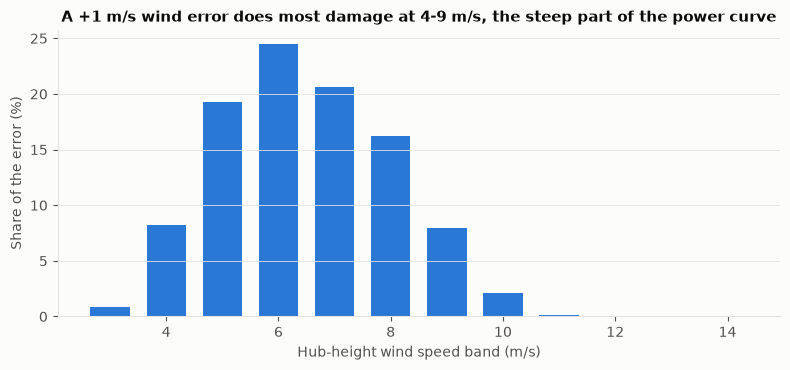

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(share.index, share.values, color=BLUE, width=0.7)
ax.set_xlabel("Hub-height wind speed band (m/s)")
ax.set_ylabel("Share of the error (%)")
ax.grid(axis="x", visible=False)
ax.set_title("A +1 m/s wind error does most damage at 4-9 m/s, the steep part of the power curve")
fig.tight_layout()
fig.savefig("figures/physics_error_by_band.png", dpi=150)
plt.show()

A steady 1 m/s error changes annual energy by about 39%, because power rises with roughly the cube of wind speed. Almost all of that comes from 4-9 m/s. Above rated speed the turbine is capped, so errors there cost almost nothing. That's why the benchmark scores power, not wind speed, and slices errors by forecast wind regime.